In [54]:
# ===== Plotting Toolkit for LEEDNet Experiments =====
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support, accuracy_score


In [55]:
# ---------------------------------------------------
# 1) Confusion matrix + metrics
# ---------------------------------------------------
def cm_and_metrics_from_preds(y_true, y_pred, class_order=(1,2,3),
                              class_names=('Normal','SSW','SW'),
                              save_path='confusion_matrix.png',
                              normalize=None):
    """
    y_true, y_pred: 1D arrays of integer labels (use your coding, default 1:N, 2:SSW, 3:SW).
    normalize: None (counts), 'true' (row-normalized), or 'pred' / 'all' (sklearn conventions)
    """
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    cm = confusion_matrix(y_true, y_pred, labels=list(class_order), normalize=normalize)
    cm_counts = confusion_matrix(y_true, y_pred, labels=list(class_order), normalize=None)

    # per-class precision/recall/F1 from counts
    prec, rec, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=list(class_order), zero_division=0
    )

    # specificity per class
    total = cm_counts.sum()
    tp = np.diag(cm_counts)
    fp = cm_counts.sum(axis=0) - tp
    fn = cm_counts.sum(axis=1) - tp
    tn = total - (tp + fp + fn)
    spe = tn / (tn + fp + 1e-12)

    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_SEN(%)": rec.mean() * 100,
        "macro_SPE(%)": spe.mean() * 100,
        "macro_F1(%)": f1.mean() * 100,
        "per_class_precision(%)": prec * 100,
        "per_class_recall_SEN(%)": rec * 100,
        "per_class_specificity(%)": spe * 100,
        "per_class_f1(%)": f1 * 100,
        "support": support,
        "cm_counts": cm_counts
    }

    # Plot
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(cm if normalize else cm_counts, cmap='Blues')
    ax.figure.colorbar(im, ax=ax)
    ax.set_xticks(np.arange(len(class_names)))
    ax.set_yticks(np.arange(len(class_names)))
    ax.set_xticklabels(class_names)
    ax.set_yticklabels(class_names)
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('True label')
    title = 'Confusion Matrix'
    if normalize == 'true':
        title += ' (Row-normalized)'
    ax.set_title(title)

    # annotations
    data_anno = cm if normalize else cm_counts
    fmt = '.2f' if normalize else 'd'
    thresh = data_anno.max() / 2.0
    for i in range(data_anno.shape[0]):
        for j in range(data_anno.shape[1]):
            ax.text(j, i, format(data_anno[i, j], fmt),
                    ha='center', va='center',
                    color='white' if data_anno[i, j] > thresh else 'black')
    plt.tight_layout()
    plt.savefig(save_path, dpi=250)
    plt.close(fig)
    return metrics

In [56]:
def cm_and_metrics_from_counts(
    M11, M12, M13, M21, M22, M23, M31, M32, M33,
    class_names=('Normal','SSW','SW'),
    save_path='confusion_matrix_from_counts.png',
    figsize=(8,6),
    font_size=16,
    annot_font_size=18,
    cmap='Blues'
):
    cm = np.array([[M11, M12, M13],
                   [M21, M22, M23],
                   [M31, M32, M33]], dtype=np.int64)

    total = cm.sum()
    tp = np.diag(cm)
    fp = cm.sum(axis=0) - tp
    fn = cm.sum(axis=1) - tp
    tn = total - (tp + fp + fn)

    prec = tp / (tp + fp + 1e-12)
    rec  = tp / (tp + fn + 1e-12)       # sensitivity
    spe  = tn / (tn + fp + 1e-12)
    f1   = 2 * prec * rec / (prec + rec + 1e-12)

    metrics = {
        "accuracy": tp.sum() / total,
        "macro_SEN(%)": rec.mean() * 100,
        "macro_SPE(%)": spe.mean() * 100,
        "macro_F1(%)": f1.mean() * 100,
        "per_class_precision(%)": prec * 100,
        "per_class_recall_SEN(%)": rec * 100,
        "per_class_specificity(%)": spe * 100,
        "per_class_f1(%)": f1 * 100,
        "cm_counts": cm
    }

    # --- Plot (bigger fonts, no grid lines) ---
    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(cm, cmap=cmap, interpolation='nearest', aspect='auto')

    # Colorbar with larger tick labels
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.ax.tick_params(labelsize=max(font_size-2, 8))

    # Ticks & labels
    ax.set_xticks(np.arange(len(class_names)))
    ax.set_yticks(np.arange(len(class_names)))
    ax.set_xticklabels(class_names, fontsize=font_size)
    ax.set_yticklabels(class_names, fontsize=font_size)

    # Axis labels & title
    ax.set_xlabel('Predicted label', fontsize=font_size+1, labelpad=10)
    ax.set_ylabel('True label', fontsize=font_size+1, labelpad=10)
    ax.set_title('Confusion Matrix - LEEDNet(Raw)', fontsize=font_size+2, pad=12)

    # Remove grid lines and extra visual clutter
    ax.grid(False)
    ax.tick_params(axis='both', which='both', length=0)  # no tick marks
    for spine in ax.spines.values():
        spine.set_visible(False)

    # Annotate cells
    thresh = cm.max() / 2.0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, f'{cm[i, j]:d}',
                    ha='center', va='center',
                    fontsize=annot_font_size,
                    color='white' if cm[i, j] > thresh else 'black')

    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.close(fig)

    return metrics



In [57]:
# ---------------------------------------------------
# 2) Segment-length vs. accuracy line chart
# ---------------------------------------------------

def plot_length_accuracy(lengths, series_dict, save_path='segment_length_plot.png',
                         base_font=20, title_font=20, legend_font=14
                         ):
    """
    lengths: list like [2,3,...,10]
    series_dict: {'LEEDNet (Raw)': [acc2, acc3, ...],
                  'Raw + FFT': [...], ...}
    """
    fig, ax = plt.subplots(figsize=(7.8, 4.8), dpi=150)

    for name, accs in series_dict.items():
        ax.plot(lengths, accs, marker='o', linewidth=2.5, markersize=6, label=name)

    ax.set_xlabel('Segment length(s)', fontsize=base_font)
    ax.set_ylabel('Accuracy', fontsize=base_font)
    ax.set_title('Accuracy vs. Segment Length', fontsize=title_font, pad=10)

    ax.tick_params(axis='both', which='major', labelsize=base_font)
    ax.grid(True, alpha=0.25, linewidth=0.8)
    ax.legend(fontsize=legend_font, frameon=True, loc='best')

    fig.tight_layout()
    fig.savefig(save_path)
    plt.close(fig)



In [58]:

# ---------------------------------------------------
# 3) Grouped bar chart for SEN/SPE/ACC/F1
# ---------------------------------------------------
def plot_sota_bars(model_names, sen, spe, acc, f1, save_path='sota_bars.png'):
    """
    model_names: list of strings
    sen/spe/acc/f1: lists (same length) — acc can be 0..1 or 0..100 (handled)
    """
    model_names = list(model_names)
    sen = np.array(sen, dtype=float)
    spe = np.array(spe, dtype=float)
    acc = np.array(acc, dtype=float)
    f1  = np.array(f1, dtype=float)

    # bring everything to percentage scale for display
    if acc.max() <= 1.0:
        acc *= 100.0

    width = 0.2
    x = np.arange(len(model_names))
    fig, ax = plt.subplots(figsize=(8.5, 4.6))
    ax.bar(x - 1.5*width, sen, width, label='SEN %')
    ax.bar(x - 0.5*width, spe, width, label='SPE %')
    ax.bar(x + 0.5*width, acc, width, label='ACC %')
    ax.bar(x + 1.5*width, f1,  width, label='F1 %')

    ax.set_xticks(x)
    ax.set_xticklabels(model_names, rotation=20, ha='right')
    ax.set_ylim(0, 100)
    ax.set_ylabel('Score (%)')
    ax.set_title('Model Comparison: SEN / SPE / ACC / F1')
    ax.grid(axis='y', alpha=0.25)
    ax.legend(ncol=4, loc='upper center', bbox_to_anchor=(0.5, 1.15))
    plt.tight_layout()
    plt.savefig(save_path, dpi=250)
    plt.close(fig)


In [59]:

# ---------------------------------------------------
# 4) t-SNE scatter (if you have 2-D embeddings & labels)
# ---------------------------------------------------
def plot_tsne_scatter(emb2d, labels, class_map={1:'Normal', 2:'SSW', 3:'SW'},
                      save_path='tsne_scatter.png'):
    """
    emb2d: array [N,2]; labels: [N] with values matching class_map keys (e.g., 1,2,3)
    """
    emb2d = np.asarray(emb2d)
    labels = np.asarray(labels)
    fig, ax = plt.subplots(figsize=(5.8, 5.2))
    for k, name in class_map.items():
        idx = np.where(labels == k)[0]
        ax.scatter(emb2d[idx, 0], emb2d[idx, 1], s=8, alpha=0.75, label=name)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title('t-SNE of final-layer embeddings')
    ax.legend()
    plt.tight_layout()
    plt.savefig(save_path, dpi=250)
    plt.close(fig)


In [60]:

# ---------------------------------------------------
# 5) 7-panel image grid for pre-saved t-SNE PNGs
# ---------------------------------------------------
def tsne_grid_7(paths, titles=None, save_path='tsne_grid.png'):
    """
    paths: list of 7 filepaths [raw, fft, wavelet, raw+fft, raw+wavelet, fft+wavelet, raw+fft+wavelet]
    titles: optional list of 7 titles
    """
    import matplotlib.image as mpimg
    assert len(paths) == 7, "Provide exactly 7 image paths."

    fig, axes = plt.subplots(2, 4, figsize=(11, 5.6))
    axes = axes.ravel()

    for i in range(7):
        img = mpimg.imread(paths[i])
        axes[i].imshow(img)
        axes[i].axis('off')
        if titles:
            axes[i].set_title(titles[i], fontsize=10)

    # Leave the 8th subplot empty
    axes[7].axis('off')

    plt.tight_layout()
    plt.savefig(save_path, dpi=250)
    plt.close(fig)


In [61]:
    # res_counts = cm_and_metrics_from_counts(
    #     M11=32456, M12=1357, M13=2750,
    #     M21=1649,  M22=9042, M23=2481,
    #     M31=1453,  M32=4350, M33=19236,
    #     class_names=('Normal','SSW','SW'),
    #     save_path='cm_LEEDnet_raw_2s.png'
    # )

res_counts = cm_and_metrics_from_counts(
        M11=32380, M12=1328, M13=2855,
        M21=1601,  M22=9273, M23=2298,
        M31=1404,  M32=4571, M33=19064,
        class_names=('Normal','SSW','SW'),
        save_path='cm_leednet_raw_2s.png'
    )
print("From counts:", res_counts)

From counts: {'accuracy': 0.8120068472998636, 'macro_SEN(%)': 78.3653435115702, 'macro_SPE(%)': 90.73295726363608, 'macro_F1(%)': 77.61637239467412, 'per_class_precision(%)': array([91.507701  , 61.11916689, 78.72155924]), 'per_class_recall_SEN(%)': array([88.55947269, 70.39933192, 76.13722593]), 'per_class_specificity(%)': array([92.13577242, 90.42401221, 89.63908716]), 'per_class_f1(%)': array([90.00945127, 65.43183743, 77.40782849]), 'cm_counts': array([[32380,  1328,  2855],
       [ 1601,  9273,  2298],
       [ 1404,  4571, 19064]])}


In [62]:
lengths = [2,3,4,5,6,7,8,9,10]
series = {
        'LEEDNet (Raw)':             [0.812,0.810,0.799,0.786,0.783,0.791,0.791,0.779,0.781],
        'Raw + FFT':                 [0.804,0.770,0.795,0.783,0.783,0.780,0.781,0.773,0.775],
        'Raw + FFT + Wavelet':       [0.766,0.772,0.761,0.756,0.750,0.730,0.742,0.726,0.733],
    }
plot_length_accuracy(lengths, series, save_path='segment_length_plot.png')


In [63]:
model_names = [
        'LEEDNet (Raw)','LEEDNet (FFT)','LEEDNet (Wavelet)',
        'Raw+FFT','FFT+Wavelet','Raw+FFT+Wavelet',
        'InceptionTime','MiniRocket','Alqarni et al.','EEGConformer','EEGNet'
    ]
sen = [78.07, 69.75, 66.06, 77.08, 72.22, 73.01, 78.56, 76.20, 76.70, 80.61, 79.85]
spe = [90.76, 87.65, 85.96, 89.74, 86.91, 88.48, 90.61, 90.11, 89.60, 90.72, 90.23]
acc = [0.812, 0.730, 0.710, 0.804, 0.758, 0.766, 0.799, 0.804, 0.792, 0.794, 0.786]
f1  = [77.49, 68.47, 65.73, 76.49, 71.28, 72.10, 76.03, 76.74, 74.60, 76.61, 75.83]
plot_sota_bars(model_names, sen, spe, acc, f1, save_path='sota_bars.png')

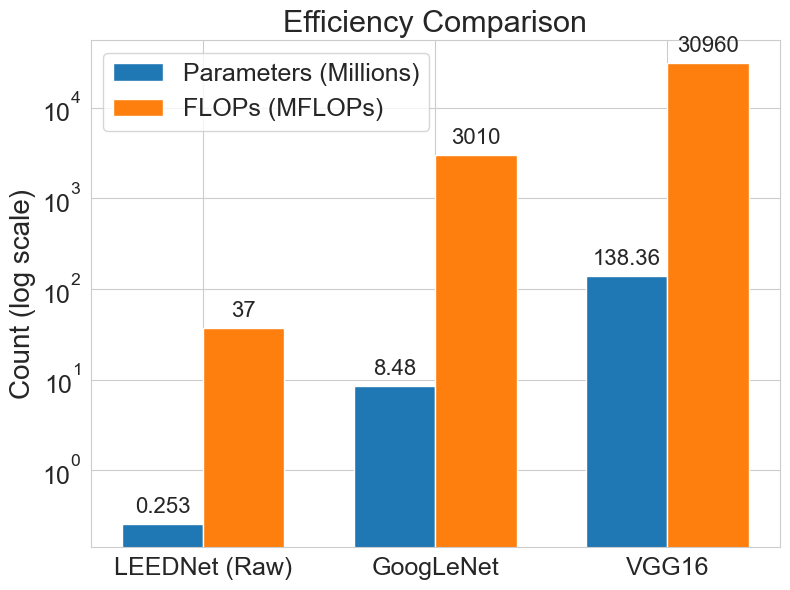

In [64]:
import matplotlib.pyplot as plt
import numpy as np

models = ['LEEDNet (Raw)', 'GoogLeNet', 'VGG16']
params_m = [0.253, 8.48, 138.36]
flops_mflops = [37, 3010, 30960]

x = np.arange(len(models))
width = 0.35

# Bigger figure
fig, ax = plt.subplots(figsize=(8, 6))

# Bars
bars1 = ax.bar(x - width/2, params_m, width, label='Parameters (Millions)')
bars2 = ax.bar(x + width/2, flops_mflops, width, label='FLOPs (MFLOPs)')

# Axis settings
ax.set_xticks(x)
ax.set_xticklabels(models, fontsize=18)
ax.set_yscale('log')

ax.set_ylabel('Count (log scale)', fontsize=20)
ax.set_title('Efficiency Comparison', fontsize=22)

# Legend
ax.legend(fontsize=18)

# Increase tick size
ax.tick_params(axis='y', labelsize=18)

# Annotate values
for bars in [bars1, bars2]:
    for b in bars:
        h = b.get_height()
        ax.text(
            b.get_x() + b.get_width()/2,
            h * 1.2,
            f'{h:g}',
            ha='center',
            va='bottom',
            fontsize=16
        )



plt.tight_layout()

# High resolution save
plt.savefig('efficiency_comparison_corrected.png', dpi=400, bbox_inches='tight')

plt.show()
